# Standardizing recording data

## Setup

In [1]:
import os
from pathlib import Path

# os.chdir("..")

prj_id = "20260303"
data_dir = Path("../data/raw/lee2024/data/textures2_data/")
proc_dir = Path("../data/processed")
proc_dir = proc_dir / prj_id
if not proc_dir.exists():
    proc_dir.mkdir()

Below quickly checks that the subjects align to the file names:

In [2]:
from scipy.io import loadmat

def get_subjects_only(file_path):
    """Loads only the subject field to save memory."""
    # variable_names restricts what is read from the disk
    data = loadmat(file_path, variable_names=['incl_subj'], simplify_cells=True)
    return data['incl_subj']

subjects = {f: get_subjects_only(os.path.join(data_dir, f)) for f in os.listdir(data_dir) if f.endswith('.mat')}
subjects

{'zz_FC_Textures2_20wk_4reps_1subj.mat': 'BB_n1',
 'zz_FC_Textures2_31wk_4reps_1subj.mat': 'BB_n1',
 'zz_FC_Textures2_35wk_4reps_1subj.mat': 'BB_n1',
 'zz_IT_Textures2_20wk_4reps_1subj.mat': 'BB_n2',
 'zz_IT_Textures2_221wk_4reps_1subj.mat': 'HT_n2',
 'zz_IT_Textures2_31wk_4reps_3subj.mat': array(['BB_n2', 'HT_IT', 'HU_n2'], dtype='<U5'),
 'zz_IT_Textures2_34wk_4reps_2subj.mat': array(['HT_IT', 'HU_n2'], dtype='<U5'),
 'zz_V1_Textures2_29wk_4reps_1subj.mat': 'KY_v1',
 'zz_V1_Textures2_37wk_4reps_2subj.mat': array(['KY_v1', 'HT_V4'], dtype='<U5'),
 'zz_V1_Textures2_56wk_4reps_1subj.mat': 'KY_v1',
 'zz_V2_Textures2_29wk_4reps_2subj.mat': array(['KY_n1', 'LI_n1'], dtype='<U5'),
 'zz_V2_Textures2_37wk_4reps_2subj.mat': array(['KY_n1', 'LI_n1'], dtype='<U5'),
 'zz_V2_Textures2_56wk_4reps_2subj.mat': array(['KY_n1', 'LI_n1'], dtype='<U5'),
 'zz_V4_Textures2_29wk_4reps_2subj.mat': array(['KY_n2', 'LI_n2'], dtype='<U5'),
 'zz_V4_Textures2_37wk_4reps_2subj.mat': array(['KY_n2', 'LI_n2'], dtype=

In [57]:
from ada import load_matlab_dir

textures2 = load_matlab_dir(data_dir, silent=False)

Loaded zz_FC_Textures2_20wk_4reps_1subj.mat as key FC_20wk.
Loaded zz_FC_Textures2_31wk_4reps_1subj.mat as key FC_31wk.
Loaded zz_FC_Textures2_35wk_4reps_1subj.mat as key FC_35wk.
Loaded zz_IT_Textures2_20wk_4reps_1subj.mat as key IT_20wk.
Loaded zz_IT_Textures2_221wk_4reps_1subj.mat as key IT_221wk.
Loaded zz_IT_Textures2_31wk_4reps_3subj.mat as key IT_31wk.
Loaded zz_IT_Textures2_34wk_4reps_2subj.mat as key IT_34wk.
Loaded zz_V1_Textures2_29wk_4reps_1subj.mat as key V1_29wk.
Loaded zz_V1_Textures2_37wk_4reps_2subj.mat as key V1_37wk.
Loaded zz_V1_Textures2_56wk_4reps_1subj.mat as key V1_56wk.
Loaded zz_V2_Textures2_29wk_4reps_2subj.mat as key V2_29wk.
Loaded zz_V2_Textures2_37wk_4reps_2subj.mat as key V2_37wk.
Loaded zz_V2_Textures2_56wk_4reps_2subj.mat as key V2_56wk.
Loaded zz_V4_Textures2_29wk_4reps_2subj.mat as key V4_29wk.
Loaded zz_V4_Textures2_37wk_4reps_2subj.mat as key V4_37wk.
Loaded zz_V4_Textures2_409wk_4reps_1subj.mat as key V4_409wk.
Loaded zz_V4_Textures2_56wk_4reps_2s

In [72]:
import pandas as pd

area_codes = pd.DataFrame([[textures2[sesh].area, textures2[sesh].wks_old] for sesh in textures2.keys()])
area_codes.columns = ["area", "wks_old"]

area_codes = (area_codes
    .sort_values(['area', 'wks_old'])
    .assign(session_no=lambda df: df.groupby(["area"]).cumcount() + 1))

In [73]:
area_codes

,area,wks_old,session_no
0,FC,20,1
1,FC,31,2
2,FC,35,3
3,IT,20,1
5,IT,31,2
6,IT,34,3
4,IT,221,4
7,V1,29,1
8,V1,37,2
9,V1,56,3


## Average spiking

### By coherence

In [109]:
from ada import avg_by_coherence
import numpy as np

coherences = {}

for sesh in textures2.keys():
    coherence_sesh = avg_by_coherence(textures2[sesh])
    coherence_avg = np.nanmean(np.stack(list(coherence_sesh.avgs.values())), axis=2)
    coherences[sesh] = coherence_avg

In [90]:
sesh_keys = area_codes[['area', 'wks_old']].apply(lambda row: '_'.join(row.values.astype(str)) + "wk", axis=1)

young_sesh_keys = list(sesh_keys[area_codes.session_no == 1])
older_sesh_keys = list(sesh_keys[area_codes.session_no == 3])

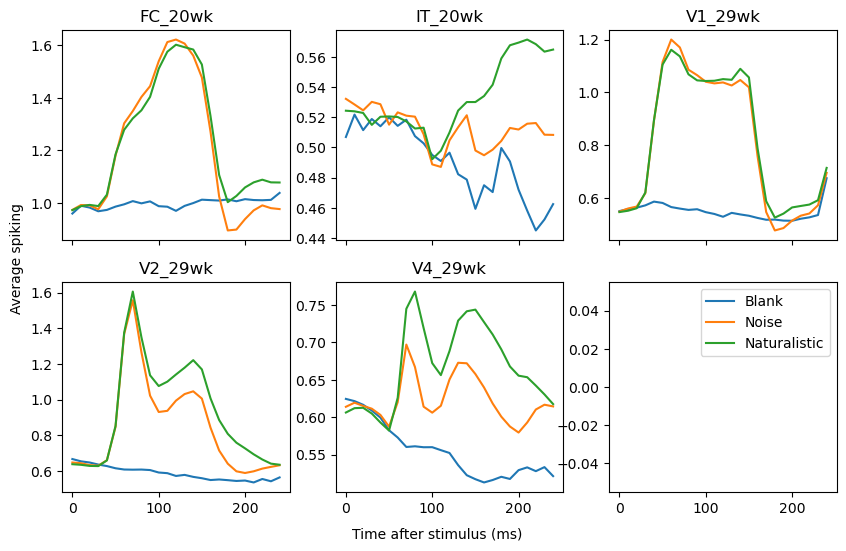

In [131]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=False)
axs_ = axs.flatten()
coherence_labels = ['Blank', 'Noise', 'Naturalistic']


for i, key in enumerate(young_sesh_keys): 
    ax = axs_[i]
    coherence_avg = coherences[key]
    for row, label in zip(coherence_avg, coherence_labels):
        ax.plot(np.arange(0, 25) * 10, row[50:75], label=label)
    ax.set_title(key)

ax = axs_[5]
for i in coherence_labels:
    ax.plot(0, 0, label=i)
ax.legend()

# Set common labels

# plt.tight_layout()
fig.text(0.5, 0.04, 'Time after stimulus (ms)', ha='center', va='center')
fig.text(0.08, 0.5, 'Average spiking', ha='center', va='center', rotation='vertical')
plt.show()

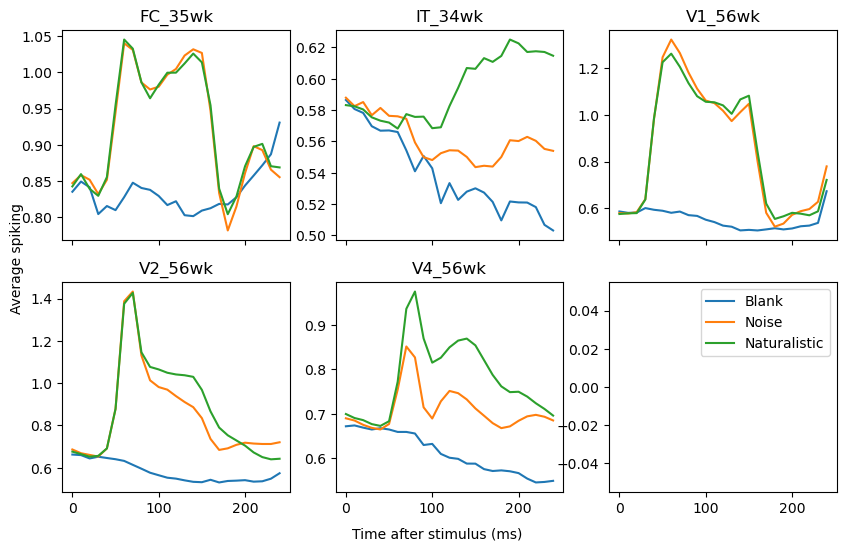

In [130]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=False)
axs_ = axs.flatten()
coherence_labels = ['Blank', 'Noise', 'Naturalistic']


for i, key in enumerate(older_sesh_keys): 
    ax = axs_[i]
    coherence_avg = coherences[key]
    for row, label in zip(coherence_avg, coherence_labels):
        ax.plot(np.arange(0, 25) * 10, row[50:75], label=label)
    ax.set_title(key)

ax = axs_[5]
for i in coherence_labels:
    ax.plot(0, 0, label=i)
ax.legend()

# Set common labels

# plt.tight_layout()
fig.text(0.5, 0.04, 'Time after stimulus (ms)', ha='center', va='center')
fig.text(0.08, 0.5, 'Average spiking', ha='center', va='center', rotation='vertical')
plt.show()

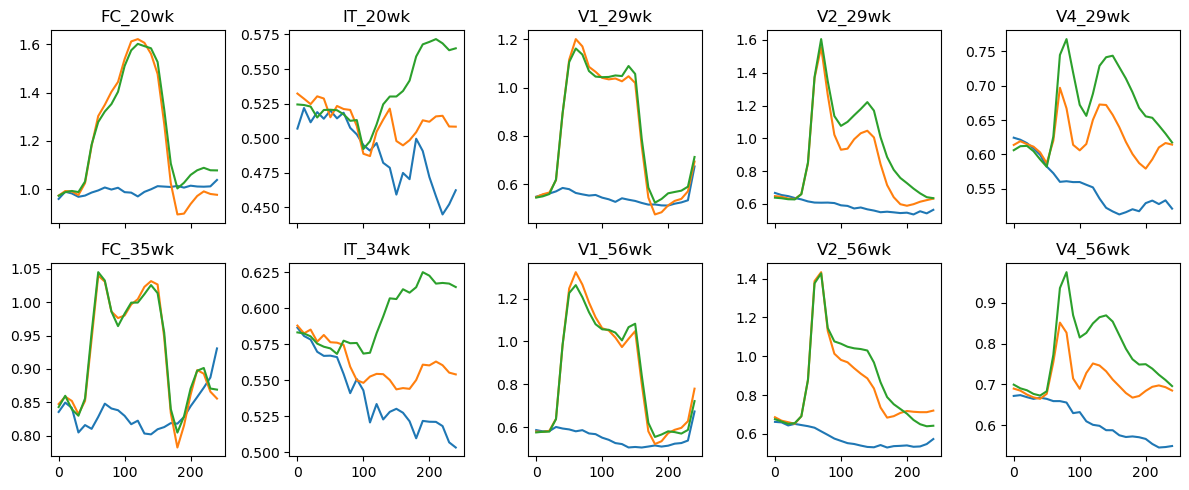

In [135]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(2, 5, figsize=(12, 5), sharex=True, sharey=False)
coherence_labels = ['Blank', 'Noise', 'Naturalistic']


for i, _ in enumerate(older_sesh_keys): 
    young_avg = coherences[young_sesh_keys[i]]
    older_avg = coherences[older_sesh_keys[i]]
    for row, label in zip(young_avg, coherence_labels):
        axs[0, i].plot(np.arange(0, 25) * 10, row[50:75], label=label)
        axs[0, i].set_title(young_sesh_keys[i])
    for row, label in zip(older_avg, coherence_labels):
        axs[1, i].plot(np.arange(0, 25) * 10, row[50:75], label=label)
        axs[1, i].set_title(older_sesh_keys[i])

plt.tight_layout()
# fig.text(0.5, 0.04, 'Time after stimulus (ms)', ha='center', va='center')
# fig.text(0.08, 0.5, 'Average spiking', ha='center', va='center', rotation='vertical')
plt.show()

## Singular value 

In [161]:
import pandas as pd 
from ada import avg_by_famsamp

temp = avg_by_famsamp(textures2["IT_20wk"])
temp = np.stack(list(temp.avgs.values()))
temp = np.nanmean(temp, axis=1)
temp.shape

(526, 96)

In [ ]:
from ada import avg_by_famsamp
import numpy as np

famsamp = {}

# average over time
for sesh in textures2.keys():
    famsamp_sesh = avg_by_famsamp(textures2[sesh])
    temp = np.stack(list(famsamp_sesh.avgs.values()))
    famsamp_avg = np.nanmean(temp, axis=1)
    famsamp[sesh] = famsamp_avg

<positron-console-cell-163>:9: RuntimeWarning: Mean of empty slice
<positron-console-cell-163>:9: RuntimeWarning: Mean of empty slice
<positron-console-cell-163>:9: RuntimeWarning: Mean of empty slice
<positron-console-cell-163>:9: RuntimeWarning: Mean of empty slice
<positron-console-cell-163>:9: RuntimeWarning: Mean of empty slice
<positron-console-cell-163>:9: RuntimeWarning: Mean of empty slice


In [177]:
singvals = {}
for i, (sesh, spikes) in enumerate(famsamp.items()):
    print(sesh)
    if spikes.ndim < 2:
        print(f"{sesh} produced an empty array.")
        continue
    try:
        S = np.linalg.svd(spikes, full_matrices=False, compute_uv=False)
    except: 
        print(f"{sesh} failed to converge")
        S = np.zeros(96)
    singvals[sesh] = S

FC_20wk
FC_31wk
FC_35wk
IT_20wk
IT_221wk
IT_31wk
IT_34wk
V1_29wk
V1_29wk failed to converge
V1_37wk
V1_37wk failed to converge
V1_56wk
V1_56wk failed to converge
V2_29wk
V2_29wk failed to converge
V2_37wk
V2_37wk failed to converge
V2_56wk
V2_56wk failed to converge
V4_29wk
V4_37wk
V4_409wk
V4_56wk
